<a href="https://colab.research.google.com/github/Hassanat718/Module-3-case-Exercise/blob/main/Module_3_Case_Exercise_2_Extreme_Value_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Case Exercise 2: Extreme Value Analysis**

## **Introduction**

Extreme Value Analysis (EVA) is used to investigate the probability
and magnitude of unusually high environmental conditions.

This exercise focuses on significant wave height (Hs) from the synthetic
Jubilee TRP3 hourly metocean dataset.

The analysis will apply two statistical approaches:

1. Generalised Extreme Value (GEV) analysis using annual and
   monthly block maxima.
2. Peaks Over Threshold (POT) analysis using threshold selection
   and the Generalised Pareto Distribution (GPD).

The return levels from both methods will be compared for
1, 10, 50 and 100-year return periods.

The analysis will also examine confidence intervals and compare
the estimated return levels with the reference values in Table 3.6.

### **Offshore Asset Integrity Relevance**

Extreme wave heights contribute to environmental loading on
offshore structures and subsea infrastructure.

Understanding the magnitude and probability of extreme wave
conditions supports environmental characterisation and
structural integrity assessment.

### **Dataset Limitation**

The dataset contains one year of hourly observations (2025).
Consequently, estimates of long return periods will have
substantial statistical uncertainty and must be interpreted
with caution.

# **Import the Python libraries**

In [1]:
# Import libraries for data manipulation and numerical calculations
import pandas as pd
import numpy as np

# Import libraries for statistical analysis
from scipy import stats
from scipy.stats import genextreme, genpareto

# Import libraries for visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualisation settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Display all columns when inspecting dataframes
pd.set_option("display.max_columns", None)

## **Data Loading**

The sythetic Jubilee TRP3 metocean dataset is loaded into a
Pandas DataFrame.

The timestamp column is converted to datetime format to support
time-based analysis, including monthly and annual block maxima.

In [2]:
# Upload the original metocean dataset
from google.colab import files
uploaded = files.upload()

# Get the uploaded filename
file_name = next(iter(uploaded))

# Read the CSV file into a DataFrame
df = pd.read_csv(file_name)

# Convert timestamp to datetime format
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Display the first five rows
df.head()

Saving Jubilee_TRP3_Metocean.csv to Jubilee_TRP3_Metocean.csv


,timestamp,Hs,season,Tp,MWD,Uc,CD,U10,SST,d
0,2025-01-01 00:00:00,1.524854,Dry,14.580621,202.472407,0.653218,236.744134,4.375462,24.497448,838
1,2025-01-01 01:00:00,1.260000,Dry,14.278740,237.042858,0.470964,295.741132,6.452242,29.514028,838
2,2025-01-01 02:00:00,1.260000,Dry,13.938506,223.919637,0.575957,285.291665,5.008258,25.771982,838
3,2025-01-01 03:00:00,1.454204,Dry,14.137886,215.919509,0.563988,281.502265,3.932616,28.473673,838
4,2025-01-01 04:00:00,1.338419,Dry,13.680172,189.361118,0.639553,31.909525,4.320759,29.308808,838


## **Dataset Overview**
We inspect the dataset dimensions and timestamp range to confirm
the number of hourly observations and the period covered by the data.

In [3]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display the first and last timestamps
print("Start date:", df["timestamp"].min())
print("End date:", df["timestamp"].max())

# Check the number of missing Hs values
print("Missing Hs values:", df["Hs"].isna().sum())

# Check the number of unique timestamps
print("Unique timestamps:", df["timestamp"].nunique())

Dataset shape: (8760, 10)
Start date: 2025-01-01 00:00:00
End date: 2025-12-31 23:00:00
Missing Hs values: 0
Unique timestamps: 8760


### **Monthly and Annual Block Maxima**

The hourly significant wave height (Hs) observations are grouped
into monthly and annual blocks.

For each block, the maximum Hs value is extracted.

The monthly analysis produces 12 maximum values, while the annual
analysis produces one maximum value.

In [4]:
# Set timestamp as the DataFrame index for time-based resampling
hs_data = df.set_index("timestamp")["Hs"].sort_index()

# Calculate the maximum Hs for each month
monthly_maxima = hs_data.resample("MS").max()

# Calculate the maximum Hs for each year
annual_maxima = hs_data.resample("YS").max()

# Display monthly maximum wave heights
print("Monthly Block Maxima:")
display(monthly_maxima)

# Display annual maximum wave height
print("\nAnnual Block Maximum:")
display(annual_maxima)

Monthly Block Maxima:


,Hs
timestamp,
2025-01-01,1.848307
2025-02-01,1.805467
2025-03-01,1.874540
2025-04-01,2.534182
2025-05-01,2.713772
2025-06-01,2.563480
2025-07-01,2.534840
2025-08-01,2.531626
2025-09-01,2.493999



Annual Block Maximum:


,Hs
timestamp,
2025-01-01,2.713772


# **Interpreting your results**
Your monthly maximum significant wave heights are:
- Highest monthly maximum: 2.7138 m in May 2025.
- Lowest monthly maximum: 1.8055 m in February 2025.
- Annual maximum: 2.7138 m, also recorded in May 2025.
This means the highest hourly significant wave height recorded throughout the entire year was approximately 2.71 m.

Notice that the annual maximum is identical to May's monthly maximum. That is expected because the annual maximum is the largest value among all 12 monthly maxima.

Important: We have 12 monthly maxima, but only one annual maximum. We can attempt an exploratory monthly GEV fit, but the sample is very small, so its long return-period estimates will be highly uncertain.

### **Visualisation of Monthly Block Maxima**

A bar chart is used to compare the maximum significant wave height
recorded in each month.

This helps identify months with relatively higher and lower
maximum wave conditions.

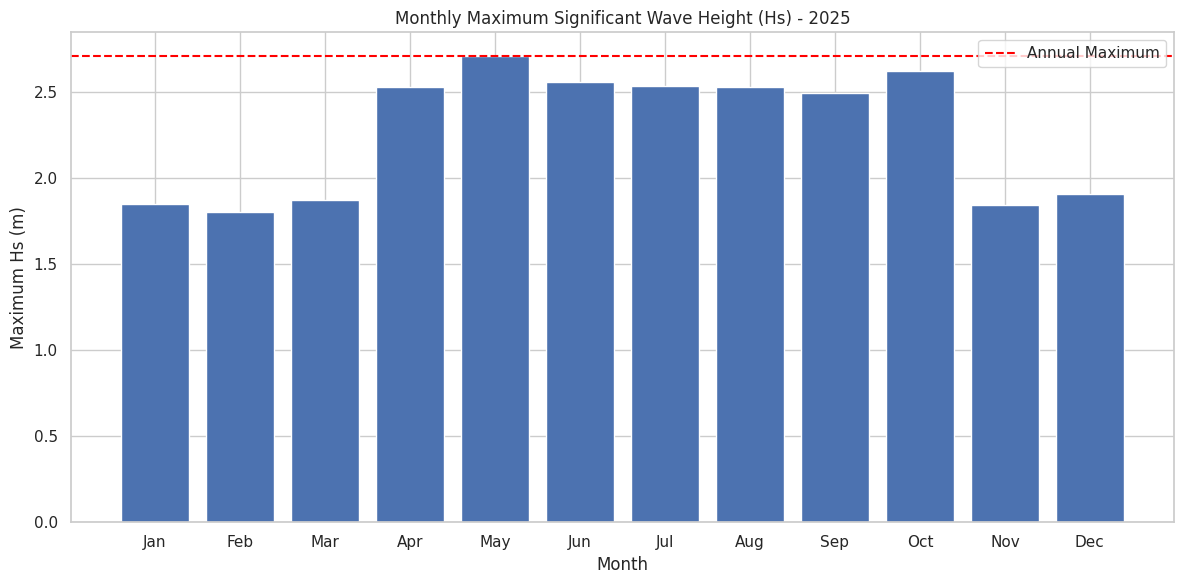

In [5]:
# Create a bar chart of monthly maximum Hs
plt.figure(figsize=(12, 6))

plt.bar(
    monthly_maxima.index.strftime("%b"),
    monthly_maxima.values
)

# Add chart labels and title
plt.title("Monthly Maximum Significant Wave Height (Hs) - 2025")
plt.xlabel("Month")
plt.ylabel("Maximum Hs (m)")

# Add a horizontal line showing the annual maximum
plt.axhline(
    y=annual_maxima.iloc[0],
    color="red",
    linestyle="--",
    label="Annual Maximum"
)

plt.legend()
plt.tight_layout()
plt.show()

### **Generalised Extreme Value (GEV) Distribution**

The GEV distribution is fitted to the monthly block maxima
to describe the statistical behaviour of extreme wave heights.

The distribution has three parameters:

- Shape (ξ): Controls the tail behaviour.
- Location (μ): Represents the central position of the distribution.
- Scale (σ): Controls the spread of the distribution.

The fit is exploratory because only 12 monthly maxima are available.

In [6]:
# Fit the GEV distribution to the monthly maximum Hs values
gev_shape, gev_location, gev_scale = genextreme.fit(monthly_maxima)

# Display the estimated parameters
print("GEV Distribution Parameters")
print("---------------------------")
print(f"Shape parameter: {gev_shape:.4f}")
print(f"Location parameter: {gev_location:.4f} m")
print(f"Scale parameter: {gev_scale:.4f} m")

GEV Distribution Parameters
---------------------------
Shape parameter: 1.0905
Location parameter: 2.2630 m
Scale parameter: 0.4916 m


### **GEV Return Level Estimation**

The fitted monthly GEV distribution is used to estimate wave-height
return levels for 10, 50 and 100-year return periods.

The annual return periods are converted to monthly probabilities
because the fitted distribution represents monthly block maxima.

The 1-year return level is not defined using the conventional
return-period formula and will be reported as unavailable.

In [7]:
# Define the return periods in years
return_periods = np.array([1, 10, 50, 100])

# Create an empty list to store the return levels
gev_return_levels = []

# Calculate the return level for each period
for T in return_periods:

    # The conventional formula is undefined for T = 1
    if T == 1:
        gev_return_levels.append(np.nan)

    else:
        # Convert annual non-exceedance probability to monthly probability
        monthly_probability = (1 - 1 / T) ** (1 / 12)

        # Calculate the corresponding GEV return level
        return_level = genextreme.ppf(
            monthly_probability,
            gev_shape,
            loc=gev_location,
            scale=gev_scale
        )

        gev_return_levels.append(return_level)

# Create a results table
gev_results = pd.DataFrame({
    "Return Period (years)": return_periods,
    "GEV Return Level (m)": gev_return_levels
})

# Display the results
display(gev_results.round(4))

,Return Period (years),GEV Return Level (m)
0,1,NaN
1,10,2.7112
2,50,2.7133
3,100,2.7136


### **GEV Upper Endpoint**

For a negative conventional GEV shape parameter, the fitted
distribution has a finite mathematical upper endpoint.

We calculate this endpoint to understand why the estimated
long-period return levels are approaching nearly the same value.

This is a property of the fitted statistical model, not proof
of a physical maximum wave height.

In [8]:
# Convert SciPy's shape parameter to the conventional EVT shape
xi = -gev_shape

# Calculate the mathematical upper endpoint
gev_upper_endpoint = gev_location - (gev_scale / xi)

print(f"Conventional shape parameter (xi): {xi:.4f}")
print(f"GEV upper endpoint: {gev_upper_endpoint:.4f} m")

Conventional shape parameter (xi): -1.0905
GEV upper endpoint: 2.7138 m


## **Peaks Over Threshold (POT) Analysis**

The POT method identifies extreme wave-height observations that
exceed a selected threshold.

The excess values above the threshold are modelled using the
Generalised Pareto Distribution (GPD).

###**Mean Residual Life Plot**

The Mean Residual Life (MRL) plot is used to investigate suitable
threshold values.

A threshold is selected by examining the region where the mean
excess values show an approximately linear relationship with
the threshold.

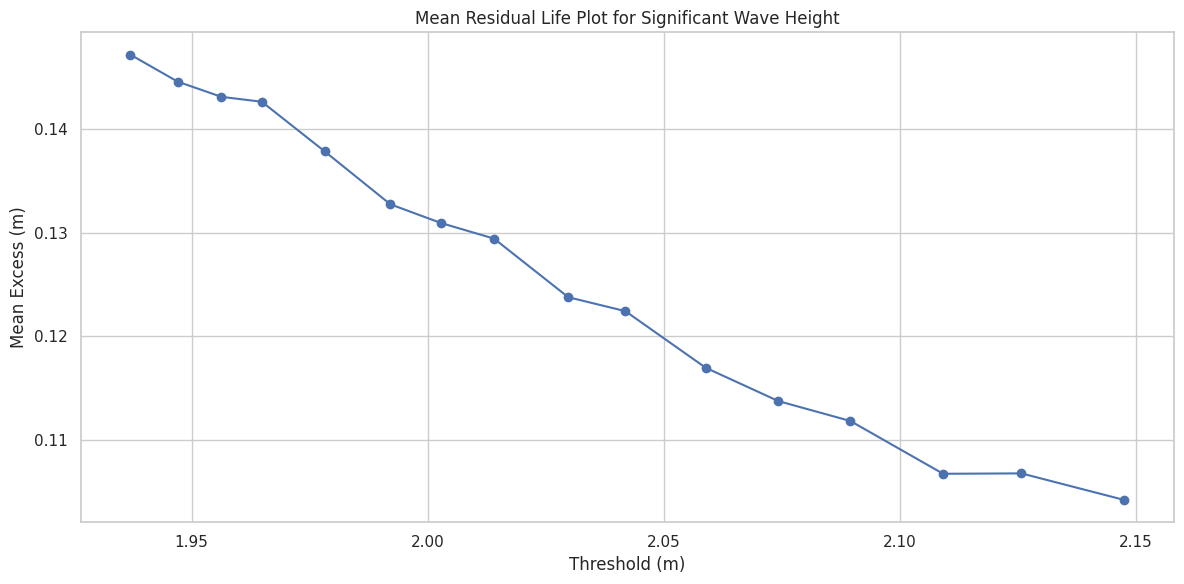

In [9]:
# Define candidate thresholds using the 80th to 95th percentiles
thresholds = np.percentile(
    hs_data,
    np.arange(80, 96, 1)
)

# Store the mean excess for each threshold
mean_excess = []

for threshold in thresholds:

    # Select observations exceeding the current threshold
    exceedances = hs_data[hs_data > threshold]

    # Calculate the average excess above the threshold
    excess = exceedances - threshold
    mean_excess.append(excess.mean())

# Plot the Mean Residual Life
plt.figure(figsize=(12, 6))

plt.plot(
    thresholds,
    mean_excess,
    marker="o"
)

plt.title("Mean Residual Life Plot for Significant Wave Height")
plt.xlabel("Threshold (m)")
plt.ylabel("Mean Excess (m)")
plt.grid(True)

plt.tight_layout()
plt.show()

# **Interpreting the MRL plot**
Three things stand out:
1. The mean excess generally decreases as the threshold increases.
2. There is no obvious region where the plot becomes consistently linear and stable.
3. The curve becomes relatively gradual around 2.00–2.10 m, but this alone is not enough to confirm a suitable threshold.
This is important. In a typical POT analysis, we look for an approximately linear section of the mean residual life plot. Your plot does not show a particularly clear one.

We should therefore avoid claiming that the MRL plot has identified a definitive threshold. Instead, we can investigate a few candidate thresholds and compare how many observations exceed each one.

### **Candidate Threshold Comparison**

Several candidate thresholds are examined to understand how the
number of exceedances changes as the threshold increases.

This provides additional information for selecting a threshold
before fitting the Generalised Pareto Distribution.

In [10]:
# Define candidate thresholds based on the MRL plot
candidate_thresholds = [1.95, 2.00, 2.05, 2.10]

# Store the number of observations above each threshold
threshold_comparison = []

for threshold in candidate_thresholds:

    # Select wave-height observations above the threshold
    exceedances = hs_data[hs_data > threshold]

    # Record the threshold and exceedance count
    threshold_comparison.append({
        "Threshold (m)": threshold,
        "Number of Exceedances": len(exceedances),
        "Percentage of Data (%)": len(exceedances) / len(hs_data) * 100
    })

# Display the comparison table
threshold_comparison_df = pd.DataFrame(threshold_comparison)

display(threshold_comparison_df.round(2))

,Threshold (m),Number of Exceedances,Percentage of Data (%)
0,1.95,1639,18.71
1,2.00,1264,14.43
2,2.05,912,10.41
3,2.10,651,7.43


Let's use 2.05 m as a provisional threshold for the next stage.

Why?
- It is towards the upper part of the candidate range.
- It retains 912 hourly exceedances for further investigation.
- It allows us to investigate relatively high wave conditions without immediately restricting the analysis to very few observations.
However, this is a working choice, not a statistically confirmed optimum. Our MRL plot did not show a clear linear region, so we will need to test threshold sensitivity later.

###  **Declustering of Threshold Exceedances**

Hourly wave-height exceedances may occur in groups during the
same storm event.

To reduce the effect of serial dependence, a 24-hour run
separation assumption is applied.

Exceedances separated by more than 24 hours are assigned to
different clusters.

The maximum Hs within each cluster represents the peak wave
height for that event.

In [11]:
# Set the provisional POT threshold
threshold = 2.05

# Select all observations above the threshold
exceedance_data = hs_data[hs_data > threshold].to_frame(name="Hs")

# Calculate the time gap between consecutive exceedances
time_gaps = exceedance_data.index.to_series().diff()

# Start a new cluster when the gap exceeds 24 hours
exceedance_data["cluster_id"] = (
    time_gaps > pd.Timedelta(hours=24)
).cumsum()

# Summarise each cluster using its peak wave height
storm_clusters = exceedance_data.groupby("cluster_id").agg(
    start_time=("Hs", lambda x: x.index.min()),
    end_time=("Hs", lambda x: x.index.max()),
    peak_Hs=("Hs", "max"),
    number_of_exceedances=("Hs", "count")
)

# Identify the time at which each cluster peak occurred
peak_times = exceedance_data.groupby("cluster_id")["Hs"].idxmax()

storm_clusters["peak_time"] = peak_times

# Display the number of independent clusters identified
print("Provisional threshold:", threshold, "m")
print("Hourly exceedances:", len(exceedance_data))
print("Identified storm clusters:", len(storm_clusters))

# Display the first five clusters
display(storm_clusters.head())

Provisional threshold: 2.05 m
Hourly exceedances: 912
Identified storm clusters: 6


,start_time,end_time,peak_Hs,number_of_exceedances,peak_time
cluster_id,,,,,
0,2025-04-01 03:00:00,2025-04-21 13:00:00,2.534182,86,2025-04-07 01:00:00
1,2025-04-23 07:00:00,2025-04-25 15:00:00,2.292699,20,2025-04-23 14:00:00
2,2025-04-27 17:00:00,2025-06-01 00:00:00,2.713772,165,2025-05-01 15:00:00
3,2025-06-02 11:00:00,2025-06-07 21:00:00,2.563480,25,2025-06-04 20:00:00
4,2025-06-09 09:00:00,2025-08-02 04:00:00,2.543452,220,2025-06-15 22:00:00


### **Declustering Sensitivity Analysis**

Different run separation intervals are tested to investigate
their influence on the number and duration of identified
threshold-exceedance clusters.

This helps assess whether the selected declustering assumption
produces meaningful independent extreme-wave events.

In [12]:
# Test different time separation intervals
run_lengths = [6, 12, 24, 48]

# Store the results
declustering_results = []

for run_length in run_lengths:

    # Calculate the time gap between consecutive exceedances
    time_gaps = exceedance_data.index.to_series().diff()

    # Start a new cluster when the gap exceeds the selected interval
    cluster_ids = (
        time_gaps > pd.Timedelta(hours=run_length)
    ).cumsum()

    # Count the resulting clusters
    number_of_clusters = cluster_ids.nunique()

    # Calculate the duration of each cluster
    cluster_durations = (
        exceedance_data.groupby(cluster_ids)
        .apply(lambda group: (
            group.index.max() - group.index.min()
        ).total_seconds() / 3600)
    )

    # Store the summary
    declustering_results.append({
        "Run Separation (hours)": run_length,
        "Number of Clusters": number_of_clusters,
        "Average Duration (hours)": cluster_durations.mean(),
        "Maximum Duration (hours)": cluster_durations.max()
    })

# Display the sensitivity results
declustering_df = pd.DataFrame(declustering_results)

display(declustering_df.round(2))

,Run Separation (hours),Number of Clusters,Average Duration (hours),Maximum Duration (hours)
0,6,286,6.45,62.0
1,12,78,47.86,169.0
2,24,6,822.50,2145.0
3,48,2,2537.00,4486.0


### **Examination of 6-Hour Declustering Results**

A provisional 6-hour run separation interval is applied.

The duration and peak wave height of each cluster are examined
to identify unusually long clusters and assess the suitability
of the declustering assumption.

In [13]:
# Set the provisional run separation interval
run_length = 6

# Calculate the time gaps between consecutive exceedances
time_gaps = exceedance_data.index.to_series().diff()

# Assign a new cluster ID when the gap exceeds 6 hours
cluster_ids = (
    time_gaps > pd.Timedelta(hours=run_length)
).cumsum()

# Calculate summary statistics for each cluster
clusters_6h = exceedance_data.groupby(cluster_ids).agg(
    start_time=("Hs", lambda x: x.index.min()),
    end_time=("Hs", lambda x: x.index.max()),
    peak_Hs=("Hs", "max"),
    number_of_exceedances=("Hs", "count")
)

# Calculate cluster duration in hours
clusters_6h["duration_hours"] = (
    clusters_6h["end_time"] - clusters_6h["start_time"]
).dt.total_seconds() / 3600

# Display the longest 10 clusters
longest_clusters = clusters_6h.sort_values(
    "duration_hours",
    ascending=False
).head(10)

display(longest_clusters.round(2))

,start_time,end_time,peak_Hs,number_of_exceedances,duration_hours
timestamp,,,,,
59,2025-05-17 21:00:00,2025-05-20 11:00:00,2.36,19,62.0
83,2025-06-12 07:00:00,2025-06-14 09:00:00,2.26,13,50.0
71,2025-05-27 06:00:00,2025-05-29 01:00:00,2.40,13,43.0
243,2025-09-28 05:00:00,2025-09-29 12:00:00,2.40,11,31.0
76,2025-06-03 06:00:00,2025-06-04 11:00:00,2.40,10,29.0
236,2025-09-20 14:00:00,2025-09-21 18:00:00,2.36,11,28.0
81,2025-06-09 09:00:00,2025-06-10 12:00:00,2.20,8,27.0
150,2025-07-25 10:00:00,2025-07-26 13:00:00,2.23,10,27.0
73,2025-05-30 04:00:00,2025-05-31 07:00:00,2.36,11,27.0


# **Interpreting the results**
the longest cluster lasts 62 hours, followed by 50 and 43 hours.

This tells us that some periods of elevated wave conditions persist for more than one or two days. That is not automatically an error: a prolonged storm or energetic sea state can produce sustained threshold exceedances.

Our current declustering results are:
- Threshold: 2.05 m
- Run separation: 6 hours
- Hourly exceedances: 912
- Identified clusters: 286

Provisional declustering choice
 We can retain the 6-hour separation for an exploratory analysis, but we should not claim that all 286 clusters are definitively independent storms. The choice needs sensitivity testing.

###**Extraction of Cluster Peak Exceedances**

The maximum significant wave height from each declustered event
is extracted.

The excess above the selected threshold is calculated as:

Excess = Cluster Peak Hs - Threshold

These cluster peak excesses will be used to fit the
Generalised Pareto Distribution (GPD).

In [14]:
# Extract the peak Hs from each 6-hour cluster
cluster_peaks = clusters_6h["peak_Hs"]

# Calculate excess wave heights above the POT threshold
cluster_excesses = cluster_peaks - threshold

# Display summary statistics
print("Number of cluster peaks:", len(cluster_peaks))
print("Threshold:", threshold, "m")
print("Minimum cluster peak:", cluster_peaks.min(), "m")
print("Maximum cluster peak:", cluster_peaks.max(), "m")
print("Mean cluster peak:", cluster_peaks.mean(), "m")

print("\nCluster Peak Excess Summary:")
display(cluster_excesses.describe().round(4))

Number of cluster peaks: 286
Threshold: 2.05 m
Minimum cluster peak: 2.053171895530421 m
Maximum cluster peak: 2.713772295415992 m
Mean cluster peak: 2.24511812329028 m

Cluster Peak Excess Summary:


,peak_Hs
count,286.0000
mean,0.1951
std,0.1245
min,0.0032
25%,0.0978
50%,0.1793
75%,0.2619
max,0.6638


**Generalised Pareto Distribution (GPD) Fitting**

The Generalised Pareto Distribution is fitted to the cluster
peak excesses above the selected threshold.

The location parameter is fixed at zero because the excesses
are measured relative to the threshold.

The fitted parameters describe the magnitude and tail behaviour
of the threshold exceedances.

In [15]:
# Fit the Generalised Pareto Distribution to cluster peak excesses
gpd_shape, gpd_location, gpd_scale = genpareto.fit(
    cluster_excesses,
    floc=0
)

# Display the fitted GPD parameters
print("Generalised Pareto Distribution Parameters")
print("-------------------------------------------")
print(f"Shape parameter: {gpd_shape:.4f}")
print(f"Location parameter: {gpd_location:.4f}")
print(f"Scale parameter: {gpd_scale:.4f} m")

Generalised Pareto Distribution Parameters
-------------------------------------------
Shape parameter: -0.3769
Location parameter: 0.0000
Scale parameter: 0.2597 m


### **Annual POT Event Rate**

The annual rate of threshold-exceedance events is calculated
using the number of declustered events divided by the observation
period in years.

This event rate is required for estimating POT return levels.

In [16]:
# Calculate the observation period in years
observation_years = (
    (hs_data.index.max() - hs_data.index.min()).total_seconds()
    / (365.25 * 24 * 3600)
)

# Calculate the annual rate of declustered events
event_rate = len(cluster_peaks) / observation_years

# Display the results
print(f"Observation period: {observation_years:.4f} years")
print(f"Number of clusters: {len(cluster_peaks)}")
print(f"Annual POT event rate: {event_rate:.2f} events/year")

Observation period: 0.9992 years
Number of clusters: 286
Annual POT event rate: 286.23 events/year


### **POT Return Level Estimation**

The fitted GPD parameters and annual event rate are used to
estimate wave-height return levels for 1, 10, 50 and 100 years.

The return levels represent model-based estimates under the
selected threshold and declustering assumptions.

These estimates are exploratory because the dataset covers
only one year.

In [17]:
# Define the return periods in years
return_periods = np.array([1, 10, 50, 100])

# Store the calculated POT return levels
pot_return_levels = []

# Calculate return levels using the POT formula
for T in return_periods:

    return_level = threshold + (gpd_scale / gpd_shape) * (
        (event_rate * T) ** gpd_shape - 1
    )

    pot_return_levels.append(return_level)

# Create a results table
pot_results = pd.DataFrame({
    "Return Period (years)": return_periods,
    "POT Return Level (m)": pot_return_levels
})

# Display the results
display(pot_results.round(4))

,Return Period (years),POT Return Level (m)
0,1,2.6574
1,10,2.7048
2,50,2.7204
3,100,2.7247


### **POT Return Levels**

The Generalized Pareto Distribution (GPD) fitted to the Peaks Over Threshold (POT) data was used to estimate significant wave heights for 1, 10, 50, and 100-year return periods.

The estimated return levels are presented in the table below.

In [18]:
# Display the GEV return-level results
print("GEV RETURN LEVELS")
display(gev_results)

# Display the POT return-level results
print("\nPOT RETURN LEVELS")
display(pot_results)

GEV RETURN LEVELS


,Return Period (years),GEV Return Level (m)
0,1,NaN
1,10,2.711193
2,50,2.713346
3,100,2.713573



POT RETURN LEVELS


,Return Period (years),POT Return Level (m)
0,1,2.657408
1,10,2.704821
2,50,2.720426
3,100,2.724727


## **POT Return Period Plot**

This plot shows the estimated significant wave heights associated with different
return periods using the fitted Generalised Pareto Distribution (GPD).

The curve is based on:
- Threshold (u): 2.05 m
- GPD shape parameter (ξ): -0.3769
- GPD scale parameter (σ): 0.2597 m
- Annual event rate (λ): 286.23 events/year

The estimates are exploratory because they are based on approximately one year
of metocean observations and a provisional declustering approach.

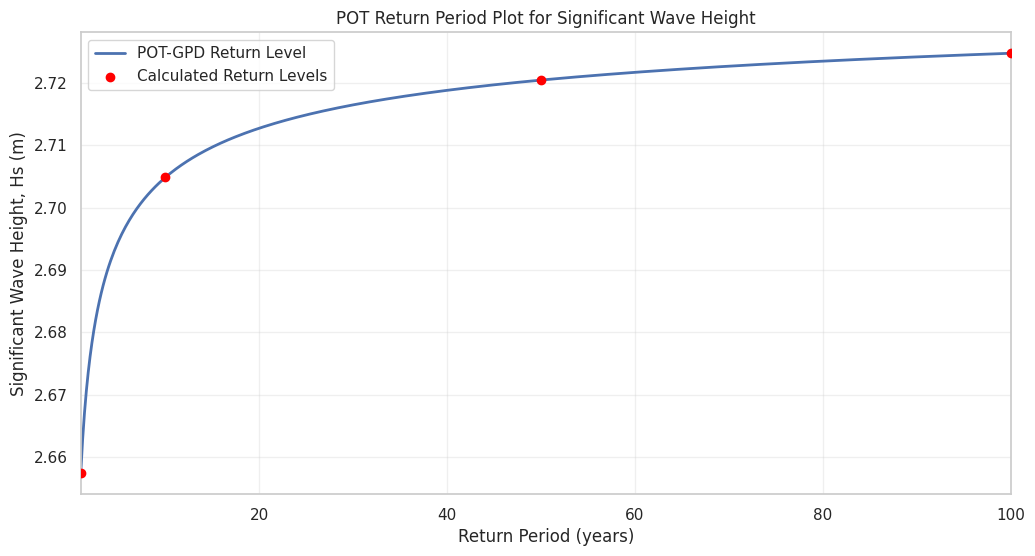

In [19]:
# Generate return periods from 1 to 100 years
T_values = np.linspace(1, 100, 500)

# Calculate POT return levels for the full range
pot_curve = threshold + (gpd_scale / gpd_shape) * (
    (event_rate * T_values) ** gpd_shape - 1
)

# Plot the POT return period curve
plt.figure(figsize=(12, 6))

plt.plot(
    T_values,
    pot_curve,
    label="POT-GPD Return Level",
    linewidth=2
)

# Add the calculated return levels as individual points
plt.scatter(
    return_periods,
    pot_return_levels,
    color="red",
    label="Calculated Return Levels",
    zorder=3
)

plt.xlabel("Return Period (years)")
plt.ylabel("Significant Wave Height, Hs (m)")
plt.title("POT Return Period Plot for Significant Wave Height")

plt.xlim(1, 100)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## **Bootstrap Confidence Intervals for POT Return Levels**

Bootstrap resampling is used to estimate the uncertainty associated with
the fitted Generalised Pareto Distribution.

The procedure is:

1. Randomly resample the observed cluster excesses with replacement.
2. Fit a new GPD to each resampled dataset.
3. Calculate the POT return levels for 1, 10, 50 and 100 years.
4. Repeat the process 1,000 times.
5. Calculate the 2.5th and 97.5th percentiles to obtain 95% bootstrap
   confidence intervals.

These intervals are conditional on the selected threshold (2.05 m),
the 6-hour declustering rule and the estimated annual event rate.
They do not account for uncertainty in those choices.

In [20]:
# Set the number of bootstrap iterations
n_bootstrap = 1000

# Store bootstrap return levels
bootstrap_results = []

# Set a random seed for reproducibility
np.random.seed(42)

# Repeat the bootstrap procedure
for i in range(n_bootstrap):

    # Randomly resample cluster excesses with replacement
    resampled_excesses = np.random.choice(
        cluster_excesses,
        size=len(cluster_excesses),
        replace=True
    )

    try:
        # Fit a GPD to the resampled excesses
        boot_shape, boot_location, boot_scale = genpareto.fit(
            resampled_excesses,
            floc=0
        )

        # Calculate return levels for each return period
        boot_levels = []

        for T in return_periods:

            if abs(boot_shape) < 1e-8:
                # Special case when the shape parameter is approximately zero
                z = threshold + boot_scale * np.log(event_rate * T)

            else:
                # Standard POT mean recurrence interval formula
                z = threshold + (boot_scale / boot_shape) * (
                    (event_rate * T) ** boot_shape - 1
                )

            boot_levels.append(z)

        bootstrap_results.append(boot_levels)

    except Exception:
        # Skip iterations where the GPD fit fails
        continue

# Convert bootstrap results into a DataFrame
bootstrap_df = pd.DataFrame(
    bootstrap_results,
    columns=return_periods
)

# Calculate the 95% confidence intervals
confidence_intervals = pd.DataFrame({
    "Return Period (years)": return_periods,
    "Lower 95% CI (m)": bootstrap_df.quantile(0.025).values,
    "Upper 95% CI (m)": bootstrap_df.quantile(0.975).values
})

# Display the confidence intervals
display(confidence_intervals.round(4))

# Report the number of successful bootstrap fits
print("Successful bootstrap iterations:", len(bootstrap_df))

,Return Period (years),Lower 95% CI (m),Upper 95% CI (m)
0,1,2.5376,2.6883
1,10,2.5505,2.7400
2,50,2.5534,2.7593
3,100,2.5540,2.7647


Successful bootstrap iterations: 1000


## **POT Return Period Plot with 95% Confidence Intervals**

This plot presents the estimated POT return levels alongside their
95% bootstrap confidence intervals.

The error bars illustrate the uncertainty in the estimated wave heights
at each return period.

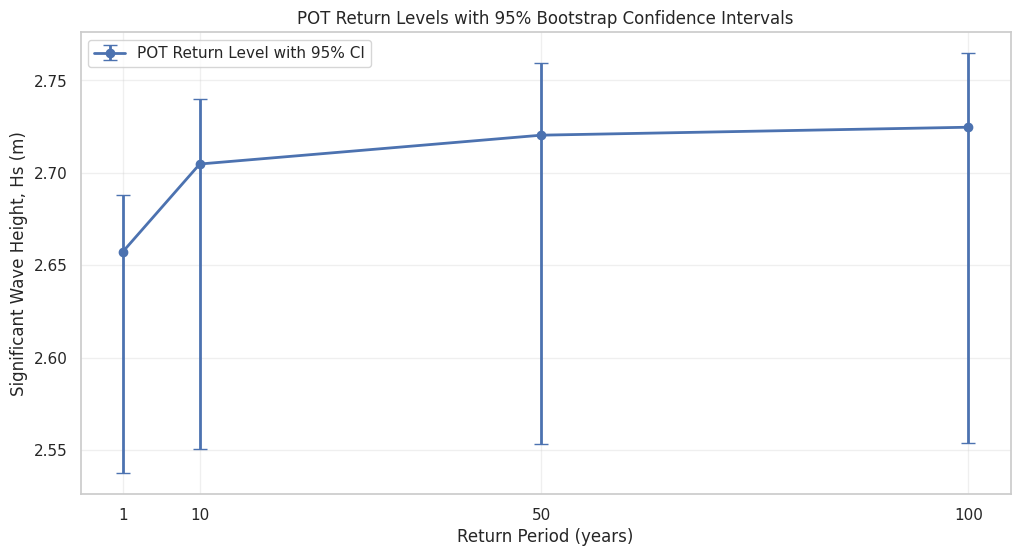

In [21]:
# Extract lower and upper confidence interval values
lower_ci = confidence_intervals["Lower 95% CI (m)"].values
upper_ci = confidence_intervals["Upper 95% CI (m)"].values

# Calculate the distance from each estimate to its confidence limits
lower_error = np.array(pot_return_levels) - lower_ci
upper_error = upper_ci - np.array(pot_return_levels)

# Plot return levels with confidence intervals
plt.figure(figsize=(12, 6))

plt.errorbar(
    return_periods,
    pot_return_levels,
    yerr=[lower_error, upper_error],
    fmt="o-",
    capsize=5,
    linewidth=2,
    label="POT Return Level with 95% CI"
)

plt.xlabel("Return Period (years)")
plt.ylabel("Significant Wave Height, Hs (m)")
plt.title("POT Return Levels with 95% Bootstrap Confidence Intervals")

plt.xticks(return_periods)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## **Comparison of GEV and POT Return Levels**

This section compares the return levels estimated using the
Generalised Extreme Value (GEV) and Peaks Over Threshold (POT) methods.

The GEV model is fitted to monthly block maxima, while the POT model
is fitted to declustered threshold exceedances.

The comparison considers 1, 10, 50 and 100-year return periods.

Note:
- The 1-year GEV return level is unavailable under the standard
  annual exceedance probability definition used in this analysis.
- The POT 1-year estimate uses the mean recurrence interval convention.
- Both methods are exploratory because the dataset covers only one year.

In [22]:
# Create a table comparing GEV and POT return levels
comparison_df = pd.DataFrame({
    "Return Period (years)": return_periods,
    "GEV Return Level (m)": gev_return_levels,
    "POT Return Level (m)": pot_return_levels
})

# Calculate the absolute difference between the two methods
comparison_df["Absolute Difference (m)"] = (
    comparison_df["GEV Return Level (m)"] -
    comparison_df["POT Return Level (m)"]
).abs()

# Display the comparison table
display(comparison_df.round(4))

,Return Period (years),GEV Return Level (m),POT Return Level (m),Absolute Difference (m)
0,1,NaN,2.6574,NaN
1,10,2.7112,2.7048,0.0064
2,50,2.7133,2.7204,0.0071
3,100,2.7136,2.7247,0.0112


### **Interpretation of GEV and POT Comparison**

The GEV and POT methods produced relatively similar return-level estimates
for the 10, 50 and 100-year return periods.

At 10 years, the GEV estimate was 2.7112 m, compared with 2.7048 m
from POT, giving an absolute difference of 0.0064 m.

At 50 and 100 years, the POT estimates were slightly higher than the
GEV estimates, with differences of 0.0071 m and 0.0112 m, respectively.

The 1-year GEV estimate was unavailable under the standard return-period
definition applied in this analysis.

Despite the close numerical agreement, the results should be treated
as exploratory. The GEV model is based on only 12 monthly maxima, while
the POT model depends on the selected threshold and declustering rule.
Furthermore, the dataset covers approximately one year.

Longer-term observations are required to obtain more reliable estimates
of extreme wave conditions for offshore engineering applications.

## **Comparison with Reference Values in Table 3.6**

The estimated significant wave height (Hs) return levels were compared
with the reference ranges provided in Table 3.6.

The 1-year POT estimate of 2.6574 m falls within the reference range
of 2.5–2.8 m.

However, both GEV and POT estimates for the 10-, 50- and 100-year
return periods fall below their respective reference ranges.

The differences may be associated with the short observation period,
limited monthly block maxima, model assumptions and differences
between the reference conditions and the dataset.

The GEV estimates also exhibit an upper-endpoint effect, resulting
in very little increase in estimated wave height at longer return
periods.

Only Hs was evaluated in this exercise. Hmax and associated Tp
were not estimated and therefore cannot be compared.

The results are exploratory and should not be used directly for
offshore engineering design without longer-term metocean data,
model validation and uncertainty assessment.

In [23]:
# Create a reference comparison table using Table 3.6 values
reference_comparison = pd.DataFrame({
    "Return Period (years)": [1, 10, 50, 100],
    "Reference Hs Lower (m)": [2.5, 3.0, 3.3, 3.5],
    "Reference Hs Upper (m)": [2.8, 3.5, 3.9, 4.2],
    "GEV Hs (m)": gev_return_levels,
    "POT Hs (m)": pot_return_levels
})

# Classify each estimate against its reference range
def assess_reference(value, lower, upper):

    if pd.isna(value):
        return "Not available"
    elif lower <= value <= upper:
        return "Within range"
    else:
        return "Below range" if value < lower else "Above range"

# Apply the comparison to both methods
reference_comparison["GEV Assessment"] = reference_comparison.apply(
    lambda row: assess_reference(
        row["GEV Hs (m)"],
        row["Reference Hs Lower (m)"],
        row["Reference Hs Upper (m)"]
    ),
    axis=1
)

reference_comparison["POT Assessment"] = reference_comparison.apply(
    lambda row: assess_reference(
        row["POT Hs (m)"],
        row["Reference Hs Lower (m)"],
        row["Reference Hs Upper (m)"]
    ),
    axis=1
)

# Display the comparison
display(reference_comparison.round(4))

,Return Period (years),Reference Hs Lower (m),Reference Hs Upper (m),GEV Hs (m),POT Hs (m),GEV Assessment,POT Assessment
0,1,2.5,2.8,NaN,2.6574,Not available,Within range
1,10,3.0,3.5,2.7112,2.7048,Below range,Below range
2,50,3.3,3.9,2.7133,2.7204,Below range,Below range
3,100,3.5,4.2,2.7136,2.7247,Below range,Below range


## **Final Comparative Return Period Plot**

This plot compares the significant wave height (Hs) return levels
estimated using the GEV and POT methods against the reference
ranges provided in Table 3.6.

The plot includes:

- GEV return-level estimates from monthly block maxima.
- POT return-level estimates with 95% bootstrap confidence intervals.
- Reference Hs ranges from Table 3.6.

The 1-year GEV estimate is unavailable under the return-period
definition used in this analysis.

The comparison is exploratory because the dataset covers
approximately one year of observations.

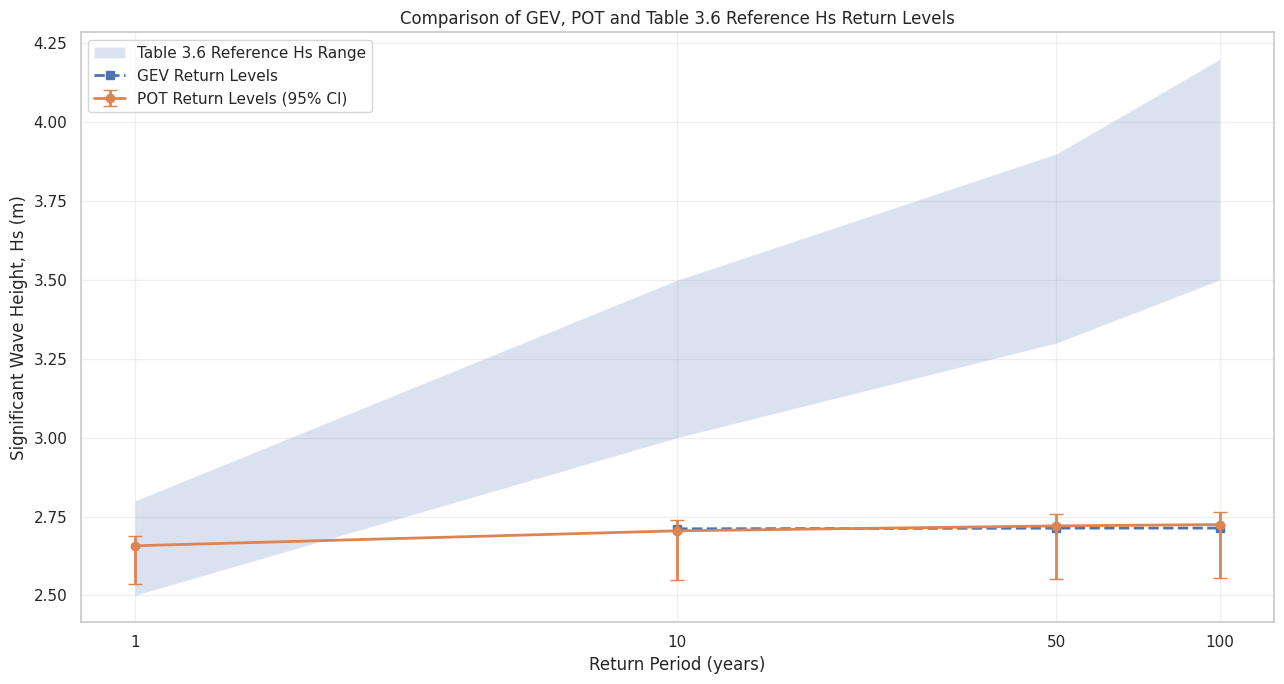

In [24]:
# Define the return periods
T = np.array([1, 10, 50, 100])

# Define the reference Hs ranges from Table 3.6
reference_lower = np.array([2.5, 3.0, 3.3, 3.5])
reference_upper = np.array([2.8, 3.5, 3.9, 4.2])

# Convert GEV and POT results into arrays
gev_values = np.array(gev_return_levels)
pot_values = np.array(pot_return_levels)

# Calculate POT confidence interval error distances
pot_lower_error = pot_values - lower_ci
pot_upper_error = upper_ci - pot_values

# Create the comparative plot
plt.figure(figsize=(13, 7))

# Plot the reference Hs ranges
plt.fill_between(
    T,
    reference_lower,
    reference_upper,
    alpha=0.2,
    label="Table 3.6 Reference Hs Range"
)

# Plot GEV return levels
plt.plot(
    T,
    gev_values,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="GEV Return Levels"
)

# Plot POT return levels with 95% confidence intervals
plt.errorbar(
    T,
    pot_values,
    yerr=[pot_lower_error, pot_upper_error],
    marker="o",
    capsize=5,
    linewidth=2,
    label="POT Return Levels (95% CI)"
)

# Configure the plot
plt.xscale("log")
plt.xticks(T, ["1", "10", "50", "100"])

plt.xlabel("Return Period (years)")
plt.ylabel("Significant Wave Height, Hs (m)")
plt.title("Comparison of GEV, POT and Table 3.6 Reference Hs Return Levels")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## **Overall Conclusion**

Extreme Value Analysis was performed on the 2025 Jubilee TRP3 metocean dataset using the Generalised Extreme Value (GEV) and Peaks Over Threshold (POT) approaches.

For the GEV analysis, monthly block maxima were extracted and fitted to a GEV distribution. The dataset provided 12 monthly maxima and one annual maximum. The fitted monthly GEV model produced return-level estimates of 2.7112 m, 2.7133 m and 2.7136 m for the 10-, 50- and 100-year return periods, respectively.

For the POT analysis, the mean residual life plot was examined to guide threshold selection. A provisional threshold of 2.05 m was selected, and a 6-hour separation interval was used for declustering. This produced 286 cluster peaks. A Generalised Pareto Distribution was fitted to the cluster excesses, resulting in a shape parameter of -0.3769 and a scale parameter of 0.2597 m.

The POT return-level estimates were 2.6574 m, 2.7048 m, 2.7204 m and 2.7247 m for the 1-, 10-, 50- and 100-year return periods, respectively. Bootstrap resampling with 1,000 iterations was used to estimate 95% confidence intervals.

Comparison with the reference values in Table 3.6 showed that the 1-year POT estimate falls within the reference Hs range of 2.5–2.8 m. However, both GEV and POT estimates for the 10-, 50- and 100-year return periods fall below their respective reference ranges.

Although the GEV and POT estimates were numerically similar, the results should be interpreted cautiously. The analysis is based on approximately one year of observations, which is insufficient for robust estimation of long return-period events. The GEV estimates are based on only 12 monthly maxima, while the POT results depend on the provisional threshold and declustering interval.

Therefore, the results provide an exploratory assessment of extreme significant wave heights rather than validated offshore design values. Longer-term metocean observations, threshold sensitivity analysis and further model validation would be required to improve the reliability of the estimates.